In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/BostonHousing.csv')
print("Первые 5 строк:")
print(df.head())
print("\nРазмер датасета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

Первые 5 строк:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

   LSTAT  MEDV  CAT. MEDV  
0   4.98  24.0          0  
1   9.14  21.6          0  
2   4.03  34.7          1  
3   2.94  33.4          1  
4   5.33  36.2          1  

Размер датасета: (506, 14)

Названия столбцов:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT', 'MEDV', 'CAT. MEDV']


In [ ]:
#MEDV — медианная стоимость жилья
y = df['MEDV']
#Используем исходные признаки, исключая целевую переменную и дополнительную категорию, рассчитанную по MEDV
X = df.drop(columns=['MEDV', 'CAT. MEDV'])
print("Количество признаков:", X.shape[1])
print("Количество объектов:", X.shape[0])

Количество признаков: 12
Количество объектов: 506


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Обучение модели завершено.")
print("Обучающих объектов:", len(X_train))
print("Тестовых объектов:", len(X_test))

Обучение модели завершено.
Обучающих объектов: 404
Тестовых объектов: 102


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE =", round(mse, 3))
print("R² =", round(r2, 3))

MSE = 22.778
R² = 0.689


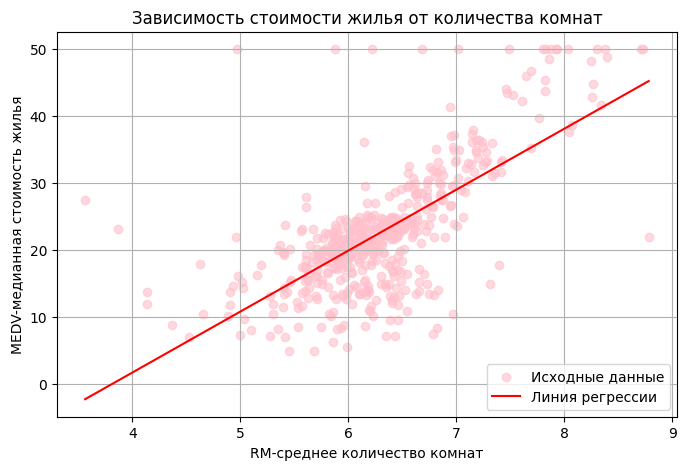

In [ ]:
plt.figure(figsize=(8, 5))
#розовые точки-исходные данные
plt.scatter( df['RM'], df['MEDV'], color='pink', alpha=0.6, label='Исходные данные' )
#Красная линия-линейная регрессия
line_model = LinearRegression()
line_model.fit(df[['RM']], df['MEDV'])
x_line = np.linspace(df['RM'].min(), df['RM'].max(), 100)
y_line = line_model.predict(pd.DataFrame({'RM': x_line}))
plt.plot( x_line, y_line, color='red', label='Линия регрессии' )
plt.xlabel('RM-среднее количество комнат')
plt.ylabel('MEDV-медианная стоимость жилья')
plt.title('Зависимость стоимости жилья от количества комнат')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
#Загружаем датасет
cancer = pd.read_csv('/content/breast_cancer.csv')
#Удаляем ненужные столбцы
cancer = cancer.drop(columns=['id', 'Unnamed: 32'])
#Выбираем признаки и целевую переменную
X = cancer.drop(columns=['diagnosis'])
y = cancer['diagnosis'].map({'B': 0, 'M': 1})
#Разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y )
#Стандартизируем признаки
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Количество признаков:", X.shape[1])
print("Обучающих объектов:", len(X_train))
print("Тестовых объектов:", len(X_test))
print("Стандартизация выполнена.")

Количество признаков: 30
Обучающих объектов: 455
Тестовых объектов: 114
Стандартизация выполнена.


In [ ]:
from sklearn.linear_model import LogisticRegression
#Создаём модель
model = LogisticRegression(max_iter=1000)
#Обучаем модель
model.fit(X_train_scaled, y_train)
#Предсказываем диагнозы
y_pred = model.predict(X_test_scaled)
print("Модель логистической регрессии обучена.")

Модель логистической регрессии обучена.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286


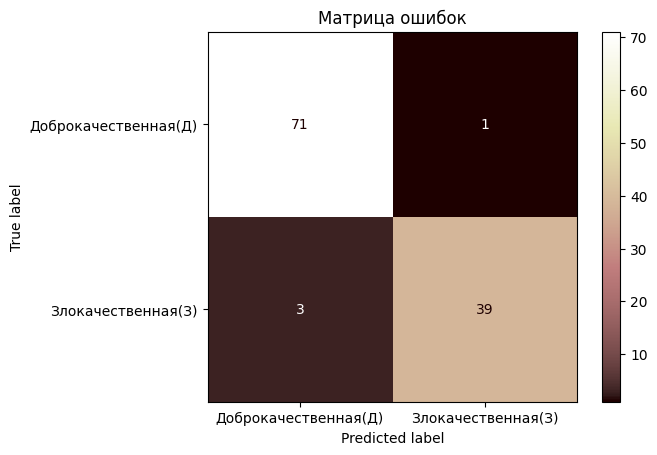

TN = 71 -доброкачественная опухоль правильно определена.
FP = 1 -доброкачественная опухоль ошибочно определена как злокачественная.
FN = 3 -злокачественная опухоль ошибочно определена как доброкачественная.
TP = 39 -злокачественная опухоль правильно определена.


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Доброкачественная(Д)', 'Злокачественная(З)']
)
disp.plot(cmap='pink', values_format='d')
plt.title('Матрица ошибок')
plt.show()
tn, fp, fn, tp = cm.ravel()
print("TN =", tn, "-доброкачественная опухоль правильно определена.")
print("FP =", fp, "-доброкачественная опухоль ошибочно определена как злокачественная.")
print("FN =", fn, "-злокачественная опухоль ошибочно определена как доброкачественная.")
print("TP =", tp, "-злокачественная опухоль правильно определена.")